# DCLDE 2027 Localization Challenge — Explainer

This notebook explains the core concepts behind whale localization using Distributed Acoustic Sensing (DAS), walks through the training data, and demonstrates physics-based and ML-based approaches.

## Table of Contents
1. [What is DAS?](#1-what-is-das)
2. [The Physical Setup](#2-the-physical-setup)
3. [How Localization Works (TDOA)](#3-how-localization-works)
4. [Exploring the Training Data](#4-exploring-the-training-data)
5. [The Arrival-Time Curve](#5-the-arrival-time-curve)
6. [Physics-Based Localization (Grid Search)](#6-physics-based-localization)
7. [Where ML Fits In](#7-where-ml-fits-in)
8. [Previous DCLDE Results & State of the Art](#8-previous-results)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from scipy.interpolate import interp1d
from scipy.optimize import minimize
import matplotlib.patches as mpatches
from pathlib import Path

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

DATA_DIR = Path('data')

---
## 1. What is DAS? <a id="1-what-is-das"></a>

**Distributed Acoustic Sensing** turns a fiber-optic cable into thousands of microphones.

A laser sends pulses down the fiber and measures tiny reflections (backscatter) from imperfections in the glass. When a sound wave hits the cable, it stretches the fiber slightly — changing the backscatter pattern. By measuring these changes at different positions along the cable, you get a "microphone" every few meters for tens of kilometers.

### Key parameters for this challenge:
| Parameter | Value | What it means |
|-----------|-------|---------------|
| Sampling rate | 200 Hz | Time resolution: 5 ms per sample |
| Channel spacing | ~2 m | Spatial resolution along cable |
| Gauge length | ~30 m | Physical averaging window |
| Cable length | 65-95 km | Total sensing aperture |
| Two fibers | North + South | Two independent arrays |

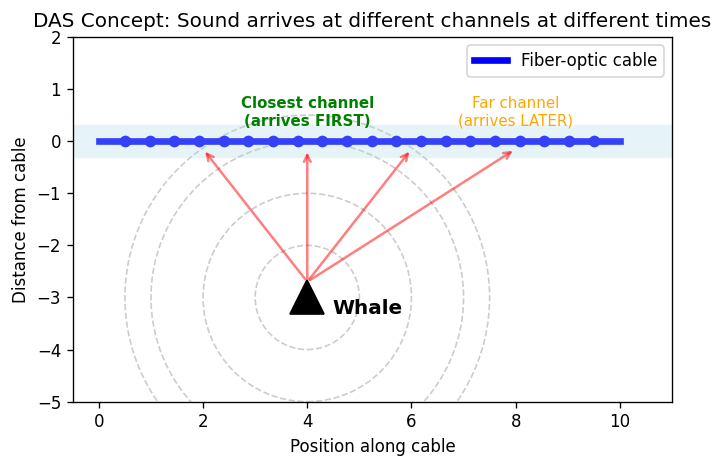

In [2]:
# Conceptual diagram: What DAS measures
fig, ax = plt.subplots(1, 1, figsize=(12, 4))

# Draw cable
cable_x = np.linspace(0, 10, 100)
cable_y = np.zeros_like(cable_x)
ax.plot(cable_x, cable_y, 'b-', linewidth=4, label='Fiber-optic cable')

# Draw channels (virtual microphones)
channel_positions = np.linspace(0.5, 9.5, 20)
for cp in channel_positions:
    ax.plot(cp, 0, 'bo', markersize=6)

# Draw whale
whale_x, whale_y = 4.0, -3.0
ax.plot(whale_x, whale_y, 'k^', markersize=20)
ax.annotate('Whale', (whale_x, whale_y), textcoords='offset points',
            xytext=(15, -10), fontsize=12, fontweight='bold')

# Draw sound waves (circles)
for r in [1, 2, 3, 3.5]:
    circle = plt.Circle((whale_x, whale_y), r, fill=False, 
                        color='gray', linestyle='--', alpha=0.4)
    ax.add_patch(circle)

# Draw arrival arrows to a few channels
for cp in [2, 4, 6, 8]:
    dist = np.sqrt((whale_x - cp)**2 + whale_y**2)
    ax.annotate('', xy=(cp, -0.15), xytext=(whale_x, whale_y + 0.3),
               arrowprops=dict(arrowstyle='->', color='red', alpha=0.5, lw=1.5))

# Labels
ax.annotate('Closest channel\n(arrives FIRST)', (4, 0.3), ha='center', 
            fontsize=9, color='green', fontweight='bold')
ax.annotate('Far channel\n(arrives LATER)', (8, 0.3), ha='center',
            fontsize=9, color='orange')

ax.set_xlim(-0.5, 11)
ax.set_ylim(-5, 2)
ax.set_xlabel('Position along cable')
ax.set_ylabel('Distance from cable')
ax.set_title('DAS Concept: Sound arrives at different channels at different times')
ax.set_aspect('equal')
ax.legend(loc='upper right')
ax.axhline(y=0, color='lightblue', alpha=0.3, linewidth=20)  # water surface hint
plt.tight_layout()
plt.show()

---
## 2. The Physical Setup <a id="2-the-physical-setup"></a>

The OOI Regional Cabled Array has two submarine fiber-optic cables running from Pacific City, Oregon out into the deep ocean:
- **North cable**: ~66 km usable length, extends toward Axial Seamount
- **South cable**: ~97 km usable length, loops south

The cables are **not straight** — they curve, which is actually helpful because it provides angular diversity for localization.

Let's look at the actual cable geometry from the training data:

In [3]:
# Load cable geometry
north_geo = pd.read_csv(DATA_DIR / 'geometry' / 'north_DAS_multicoord.csv')
south_geo = pd.read_csv(DATA_DIR / 'geometry' / 'south_DAS_multicoord.csv')

print(f"North cable: {len(north_geo)} channels, {north_geo['chan_m'].max()/1000:.1f} km")
print(f"South cable: {len(south_geo)} channels, {south_geo['chan_m'].max()/1000:.1f} km")
print(f"\nGeometry columns: {list(north_geo.columns)}")
print(f"\nFirst few rows (North):")
north_geo.head()

North cable: 31518 channels, 66.3 km
South cable: 46440 channels, 96.7 km

Geometry columns: ['chan_idx', 'lat', 'lon', 'depth', 'chan_m', 'utm_x', 'utm_y', 'x', 'y']

First few rows (North):


,chan_idx,lat,lon,depth,chan_m,utm_x,utm_y,x,y
0,942.0,45.202300,-123.96715,7.066498,1923.474216,424042.519241,5.005879e+06,11183.561634,20767.186709
1,943.0,45.202296,-123.96718,6.922533,1925.516121,424040.157796,5.005878e+06,11185.923079,20766.770569
2,944.0,45.202292,-123.96720,6.814611,1927.558025,424038.581725,5.005878e+06,11187.499151,20766.345021
3,945.0,45.202288,-123.96723,6.644497,1929.599930,424036.220279,5.005877e+06,11189.860596,20765.928882
4,946.0,45.202284,-123.96725,6.523548,1931.641835,424034.644207,5.005877e+06,11191.436668,20765.503336


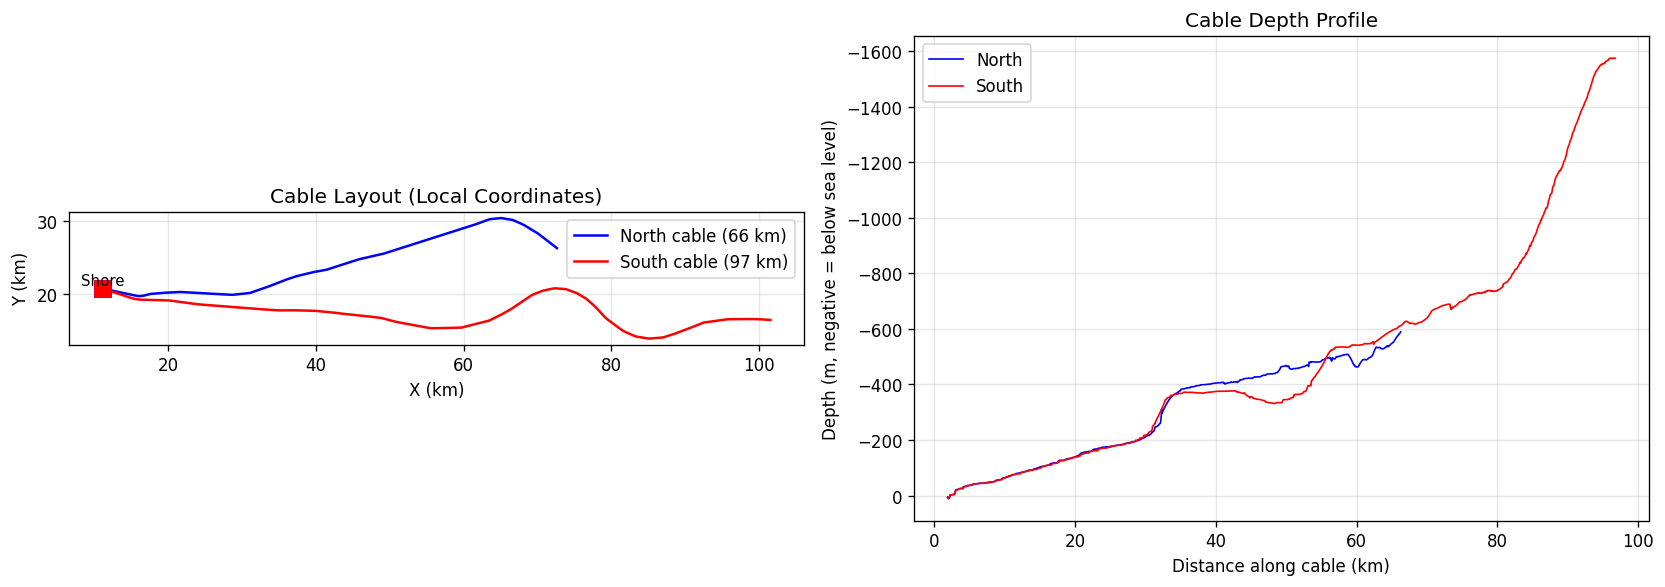


Key observations:
  - Both cables start at the SAME point near shore
  - North cable curves UP (higher Y), South cable stays LOW (lower Y)
  - Max depth: North=-589m, South=-1575m
  - The ~5km Y separation between cables provides angular diversity for L-2


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Map view (x, y coordinates)
ax = axes[0]
ax.plot(north_geo['x'].values[::5]/1000, north_geo['y'].values[::5]/1000, 
        'b-', linewidth=1.5, label=f'North cable ({north_geo["chan_m"].max()/1000:.0f} km)')
ax.plot(south_geo['x'].values[::5]/1000, south_geo['y'].values[::5]/1000, 
        'r-', linewidth=1.5, label=f'South cable ({south_geo["chan_m"].max()/1000:.0f} km)')

# Mark start (shore) and end (deep ocean)
ax.plot(north_geo['x'].iloc[0]/1000, north_geo['y'].iloc[0]/1000, 'bs', markersize=10)
ax.plot(south_geo['x'].iloc[0]/1000, south_geo['y'].iloc[0]/1000, 'rs', markersize=10)
ax.annotate('Shore', (north_geo['x'].iloc[0]/1000, north_geo['y'].iloc[0]/1000 + 0.5),
            ha='center', fontsize=9)

ax.set_xlabel('X (km)')
ax.set_ylabel('Y (km)')
ax.set_title('Cable Layout (Local Coordinates)')
ax.legend()
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Plot 2: Depth profile
ax = axes[1]
ax.plot(north_geo['chan_m'].values[::5]/1000, north_geo['depth'].values[::5], 
        'b-', linewidth=1, label='North')
ax.plot(south_geo['chan_m'].values[::5]/1000, south_geo['depth'].values[::5], 
        'r-', linewidth=1, label='South')
ax.set_xlabel('Distance along cable (km)')
ax.set_ylabel('Depth (m, negative = below sea level)')
ax.set_title('Cable Depth Profile')
ax.legend()
ax.grid(True, alpha=0.3)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

print(f"\nKey observations:")
print(f"  - Both cables start at the SAME point near shore")
print(f"  - North cable curves UP (higher Y), South cable stays LOW (lower Y)")
print(f"  - Max depth: North={north_geo['depth'].min():.0f}m, South={south_geo['depth'].min():.0f}m")
print(f"  - The ~5km Y separation between cables provides angular diversity for L-2")

---
## 3. How Localization Works (TDOA) <a id="3-how-localization-works"></a>

### The Core Idea: Time Difference of Arrival

When a whale calls at position `(wx, wy)`:
1. Sound travels outward at speed `c ≈ 1480 m/s`
2. It hits different parts of the cable at different times
3. The **closest** cable point receives the sound first
4. Points farther away receive it later

The arrival time at channel `i` located at `(xi, yi)` is:

$$t_i = t_0 + \frac{\sqrt{(w_x - x_i)^2 + (w_y - y_i)^2}}{c}$$

Where:
- $t_0$ = unknown emission time (when the whale actually called)
- $c$ = sound speed in water (~1480 m/s)

### Why is this NOT simple triangulation?

**Traditional triangulation** uses discrete sensors (3+ hydrophones) and measures time differences between pairs. With 3 sensors you get 2 independent TDOAs → 2 hyperbolas → intersection = position.

**DAS is different** — you have THOUSANDS of continuous measurement points along a cable. Instead of 2-3 discrete time differences, you observe the **entire arrival-time curve** across all channels simultaneously. This is much more information!

The shape of this curve (a hyperbola) directly encodes:
- **Where the minimum is** → closest cable point to the whale (tells you position along cable)
- **How sharp the minimum is** → how far away the whale is (closer = sharper V-shape)
- **Asymmetry** → whale not perpendicular to cable

Let's visualize this:

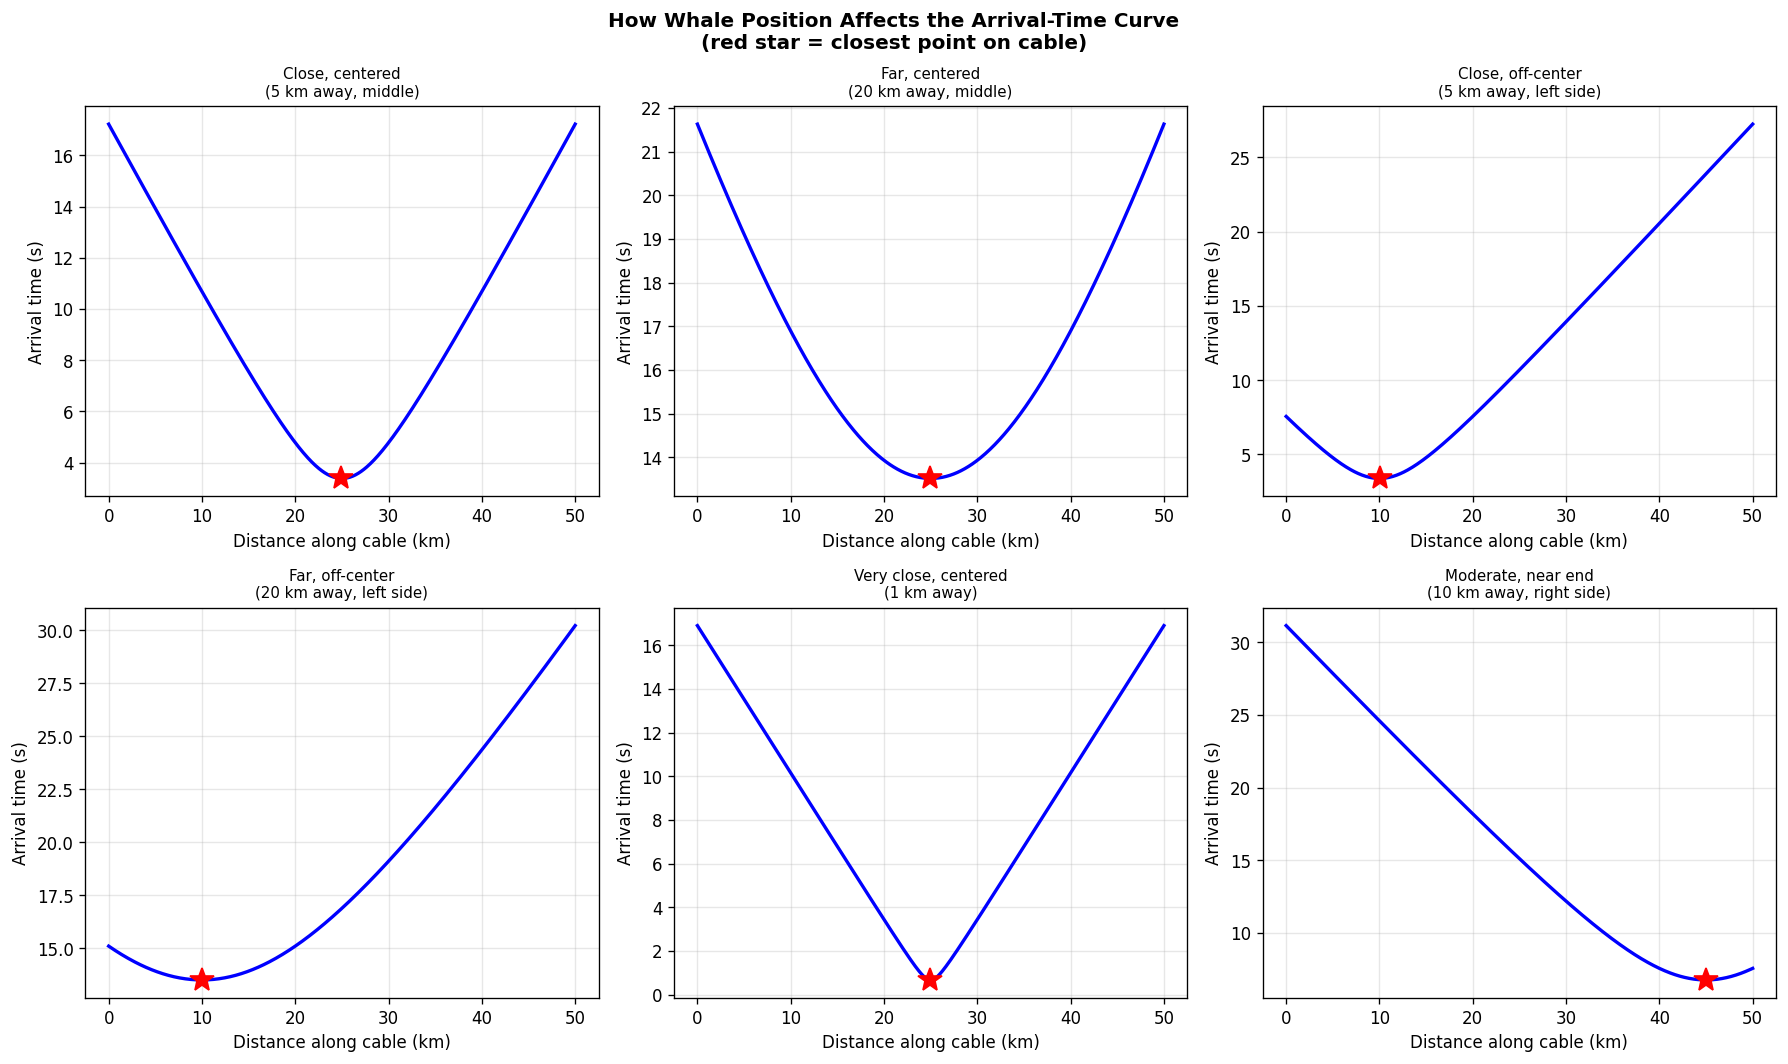

KEY OBSERVATIONS:
  1. CLOSE whale → sharp V-shape (curvature is strong)
  2. FAR whale → flat, gentle curve (harder to localize!)
  3. OFF-CENTER → asymmetric curve (one arm steeper than the other)
  4. The MINIMUM tells you where along the cable the whale is closest
  5. The CURVATURE tells you how far away the whale is

  → With one cable: you know position along + distance perpendicular
  → BUT you don't know WHICH SIDE (left/right ambiguity!)
  → With two cables: the ambiguity is resolved


In [5]:
# Demonstrate how whale position affects the arrival-time curve shape
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# Simplified straight cable for demonstration
cable_positions = np.linspace(0, 50000, 500)  # 50 km cable
cable_x = cable_positions
cable_y = np.zeros_like(cable_positions)
c = 1480.0  # sound speed

# Different whale positions to show how curve shape changes
whale_scenarios = [
    {'wx': 25000, 'wy': 5000, 'label': 'Close, centered\n(5 km away, middle)'},
    {'wx': 25000, 'wy': 20000, 'label': 'Far, centered\n(20 km away, middle)'},
    {'wx': 10000, 'wy': 5000, 'label': 'Close, off-center\n(5 km away, left side)'},
    {'wx': 10000, 'wy': 20000, 'label': 'Far, off-center\n(20 km away, left side)'},
    {'wx': 25000, 'wy': 1000, 'label': 'Very close, centered\n(1 km away)'},
    {'wx': 45000, 'wy': 10000, 'label': 'Moderate, near end\n(10 km away, right side)'},
]

for idx, scenario in enumerate(whale_scenarios):
    ax = axes[idx // 3, idx % 3]
    wx, wy = scenario['wx'], scenario['wy']
    
    # Compute arrival times
    distances = np.sqrt((wx - cable_x)**2 + (wy - cable_y)**2)
    arrival_times = distances / c
    
    ax.plot(cable_positions/1000, arrival_times, 'b-', linewidth=2)
    
    # Mark minimum
    min_idx = np.argmin(arrival_times)
    ax.plot(cable_positions[min_idx]/1000, arrival_times[min_idx], 'r*', markersize=15)
    
    ax.set_xlabel('Distance along cable (km)')
    ax.set_ylabel('Arrival time (s)')
    ax.set_title(scenario['label'], fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('How Whale Position Affects the Arrival-Time Curve\n'
             '(red star = closest point on cable)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("KEY OBSERVATIONS:")
print("  1. CLOSE whale → sharp V-shape (curvature is strong)")
print("  2. FAR whale → flat, gentle curve (harder to localize!)")
print("  3. OFF-CENTER → asymmetric curve (one arm steeper than the other)")
print("  4. The MINIMUM tells you where along the cable the whale is closest")
print("  5. The CURVATURE tells you how far away the whale is")
print("\n  → With one cable: you know position along + distance perpendicular")
print("  → BUT you don't know WHICH SIDE (left/right ambiguity!)")
print("  → With two cables: the ambiguity is resolved")

### Why NOT simple triangulation?

You asked about triangulation. Here's the key distinction:

| | Traditional Triangulation | DAS Localization |
|---|---|---|
| **Sensors** | 3-5 discrete hydrophones | 10,000+ continuous channels |
| **Measurements** | 2-4 time differences | Entire arrival-time curve |
| **Information** | Sparse (2-4 numbers) | Dense (thousands of points) |
| **Geometry** | Known fixed positions | Known cable path |
| **Method** | Solve 2-3 hyperbola intersections | Fit entire curve to a model |
| **Advantage** | Simple math | Massive redundancy → robustness |

The DAS approach is **much more overdetermined** than triangulation. With 3 hydrophones you get a unique solution (when it exists). With DAS you have thousands of redundant measurements, so you can:
- Reject outliers (bad picks)
- Estimate uncertainty
- Handle systematic errors (non-constant sound speed)

It's like the difference between fitting a line through 2 points vs fitting a line through 1000 points — the latter is far more robust.

**However**, the fundamental physics is the same: you're using time-of-flight differences to infer position. The "triangulation" intuition isn't wrong — it's just that DAS gives you a continuous, overdetermined version of it.

---
## 4. Exploring the Training Data <a id="4-exploring-the-training-data"></a>

The training data has three components:

1. **`geometry/`** — Cable coordinates (channel → lat/lon/x/y/depth)
2. **`annotations/`** — Arrival-time picks (the key input for localization)
3. **`detections/`** — Raw denoised DAS data as NetCDF files (~0.5-1 GB each)

The annotations are organized into **5 batches** (different 10-minute time windows), each with files for North and South cables.

In [6]:
# Load sample annotations
ann_n = pd.read_csv(DATA_DIR / 'annotations' / 'annotated_calls_north_batch1_sample.csv')
ann_s = pd.read_csv(DATA_DIR / 'annotations' / 'annotated_calls_south_batch1_sample.csv')

print("=== Annotation Structure ===")
print(f"\nColumns: {list(ann_n.columns)}")
print(f"\nColumn meanings:")
print(f"  call_id    : Which whale call this pick belongs to (same ID = same call)")
print(f"  segment_id : Cable segment where pick was made")
print(f"  utc_time   : Absolute timestamp")
print(f"  time       : Arrival time in seconds (relative to file start)")
print(f"  dist       : Distance along cable in meters (maps to geometry)")
print(f"  call_type  : HF (high-freq, 27→19 Hz) or LF (low-freq, 20→17 Hz)")
print(f"  cable      : Which fiber (North/South)")
print(f"  snr        : Signal-to-noise ratio at this pick")
print(f"  filename   : Source NetCDF file")

print(f"\n\n=== Data Summary ===")
print(f"North cable picks: {len(ann_n)} rows, {ann_n['call_id'].nunique()} unique calls")
print(f"South cable picks: {len(ann_s)} rows, {ann_s['call_id'].nunique()} unique calls")
print(f"\nCall types: {ann_n['call_type'].value_counts().to_dict()}")
print(f"\nShared call_ids (detected on BOTH cables): {sorted(set(ann_n.call_id) & set(ann_s.call_id))}")

=== Annotation Structure ===

Columns: ['call_id', 'segment_id', 'utc_time', 'time', 'dist', 'call_type', 'cable', 'snr', 'filename']

Column meanings:
  call_id    : Which whale call this pick belongs to (same ID = same call)
  segment_id : Cable segment where pick was made
  utc_time   : Absolute timestamp
  time       : Arrival time in seconds (relative to file start)
  dist       : Distance along cable in meters (maps to geometry)
  call_type  : HF (high-freq, 27→19 Hz) or LF (low-freq, 20→17 Hz)
  cable      : Which fiber (North/South)
  snr        : Signal-to-noise ratio at this pick
  filename   : Source NetCDF file


=== Data Summary ===
North cable picks: 180 rows, 12 unique calls
South cable picks: 166 rows, 10 unique calls

Call types: {'HF': 121, 'LF': 59}

Shared call_ids (detected on BOTH cables): [1, 3, 6, 7, 9, 10, 13]


In [7]:
# Show example picks for one call
print("=== Example: Call ID 1 on North Cable ===")
print("Each row = one arrival-time pick at a specific cable position")
print()
call1_n = ann_n[ann_n['call_id'] == 1].sort_values('dist')
print(call1_n[['call_id', 'time', 'dist', 'call_type', 'snr']].to_string(index=False))
print(f"\n→ {len(call1_n)} picks spanning {call1_n['dist'].min()/1000:.1f} to {call1_n['dist'].max()/1000:.1f} km along cable")
print(f"→ Arrival times span {call1_n['time'].min():.1f} to {call1_n['time'].max():.1f} seconds")

=== Example: Call ID 1 on North Cable ===
Each row = one arrival-time pick at a specific cable position

 call_id      time         dist call_type       snr
       1 15.541167 14931.001101        HF 18.886488
       1 13.963894 17127.538411        HF 22.616548
       1 13.122682 18345.490188        HF 14.322891
       1 11.850849 20246.339784        HF 22.557636
       1 10.393749 22527.359298        HF 25.701684
       1  9.146952 24048.038974        HF 21.349245
       1  8.185567 25498.316813        HF 26.120531
       1  7.469535 26596.585468        HF 23.855313
       1  6.803575 27511.809348        HF 20.528616
       1  6.367947 28265.109002        HF 23.368839
       1  6.943777 29032.489024        HF 23.338282
       1  8.290718 31116.383395        HF 24.536040
       1  9.222060 32468.098663        HF 19.531438
       1 10.774297 34749.118177        HF 15.322158
       1 12.101209 36762.610711        HF 17.530735
       1 13.503230 38790.183613        HF 20.691916
       1 16

### Understanding what each pick represents

Each row in the annotations table is **one measurement**: "at this point on the cable (`dist`), the whale call arrived at this time (`time`)".

Multiple picks from the same `call_id` together trace out the arrival-time curve — the hyperbola we discussed. The **same call** can be detected on both the North and South cables (same `call_id`).

The picks are **sparse** — not every channel has a pick, only the ones where the call was clearly detected above noise (indicated by the `snr` column).

---
## 5. The Arrival-Time Curve <a id="5-the-arrival-time-curve"></a>

This is the **single most important concept** for this challenge. Let's visualize real picks from the data:

In [8]:
# Build interpolators for mapping cable distance → physical position
interp_x_n = interp1d(north_geo['chan_m'].values, north_geo['x'].values, 
                       kind='linear', fill_value='extrapolate')
interp_y_n = interp1d(north_geo['chan_m'].values, north_geo['y'].values, 
                       kind='linear', fill_value='extrapolate')
interp_x_s = interp1d(south_geo['chan_m'].values, south_geo['x'].values, 
                       kind='linear', fill_value='extrapolate')
interp_y_s = interp1d(south_geo['chan_m'].values, south_geo['y'].values, 
                       kind='linear', fill_value='extrapolate')

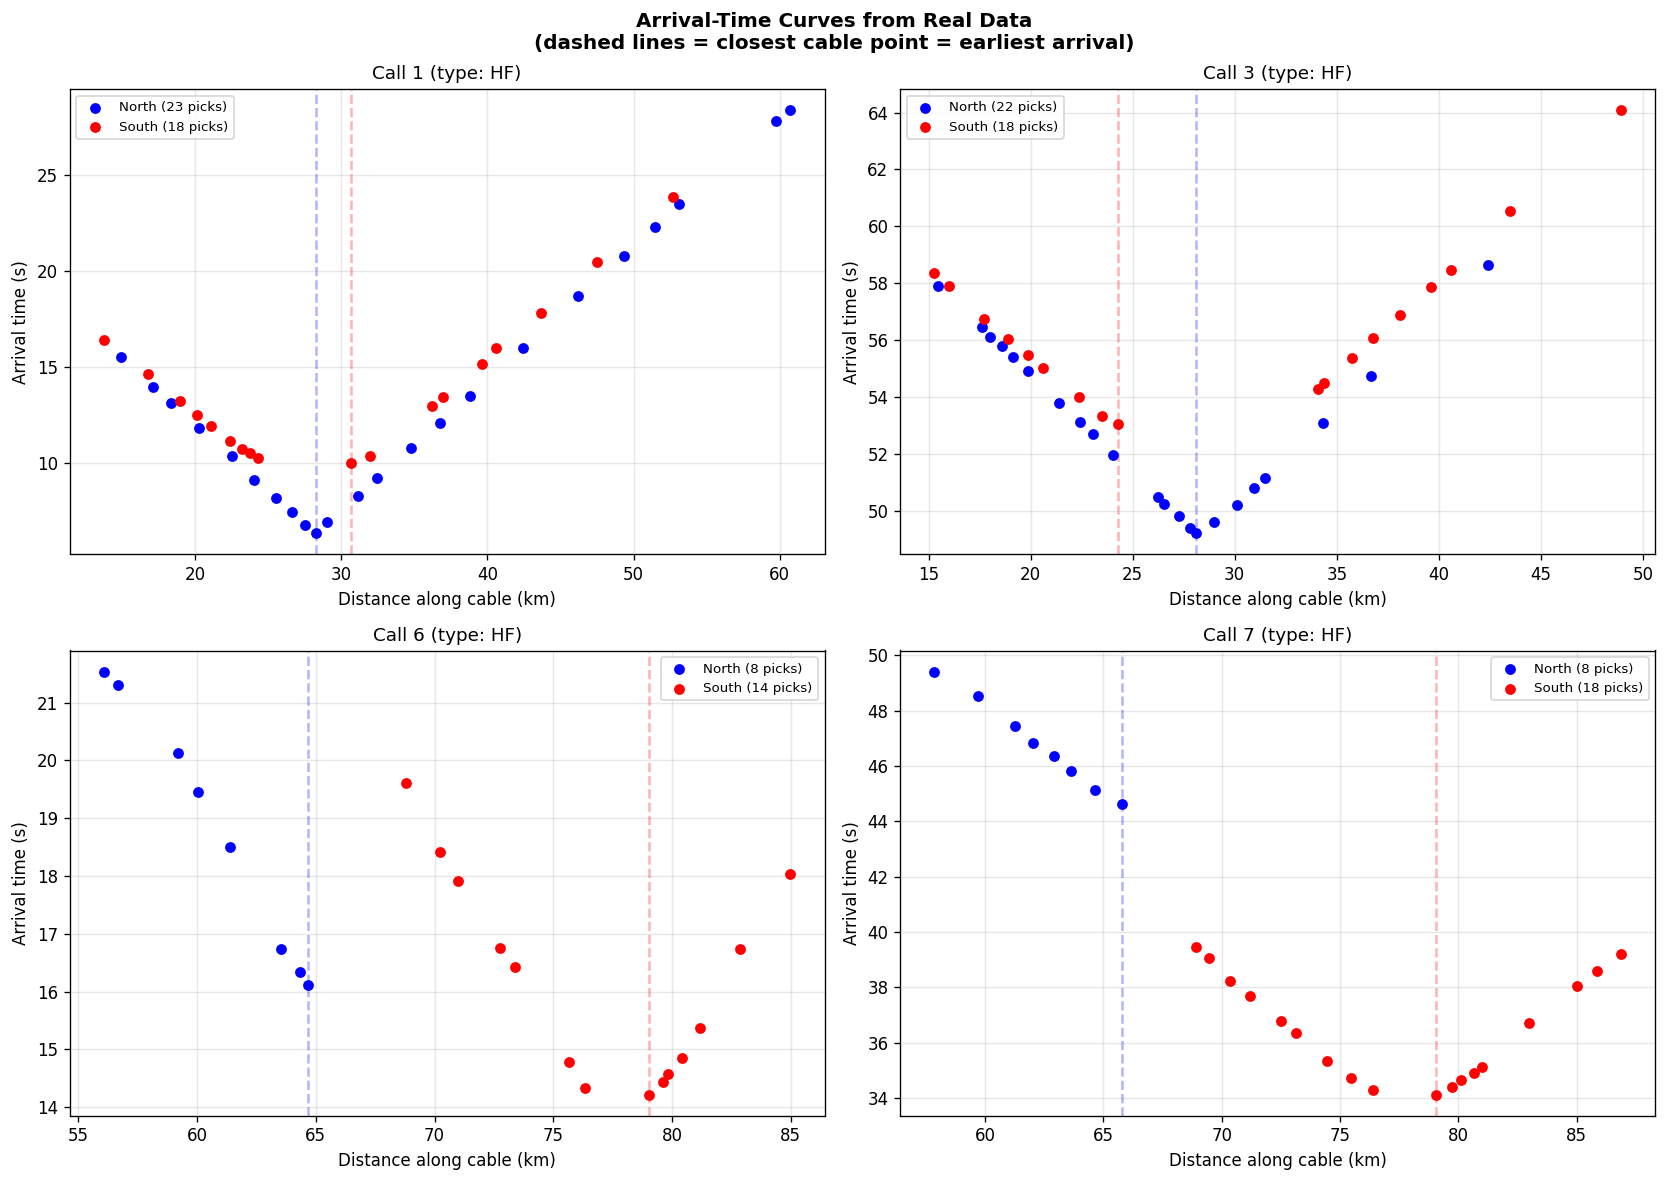

WHAT YOU'RE SEEING:
  - Each dot = one picked arrival time at a specific cable position
  - The V-shape (hyperbola) is the whale's 'signature'
  - Blue dots = North cable, Red dots = South cable
  - Dashed lines mark the cable point closest to the whale
  - Different calls have different shapes → different whale positions!


In [9]:
# Visualize arrival-time curves for multiple calls
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Get shared call_ids (visible on both cables)
shared_calls = sorted(set(ann_n.call_id) & set(ann_s.call_id))

for idx, call_id in enumerate(shared_calls[:4]):
    ax = axes[idx // 2, idx % 2]
    
    cn = ann_n[ann_n['call_id'] == call_id].sort_values('dist')
    cs = ann_s[ann_s['call_id'] == call_id].sort_values('dist')
    
    ax.scatter(cn['dist']/1000, cn['time'], c='blue', s=30, 
              label=f'North ({len(cn)} picks)', zorder=5)
    ax.scatter(cs['dist']/1000, cs['time'], c='red', s=30, 
              label=f'South ({len(cs)} picks)', zorder=5)
    
    # Mark the earliest arrival on each cable
    if len(cn) > 0:
        min_n = cn.loc[cn['time'].idxmin()]
        ax.axvline(min_n['dist']/1000, color='blue', alpha=0.3, linestyle='--')
    if len(cs) > 0:
        min_s = cs.loc[cs['time'].idxmin()]
        ax.axvline(min_s['dist']/1000, color='red', alpha=0.3, linestyle='--')
    
    call_type = cn['call_type'].iloc[0] if len(cn) > 0 else cs['call_type'].iloc[0]
    ax.set_title(f'Call {call_id} (type: {call_type})', fontsize=11)
    ax.set_xlabel('Distance along cable (km)')
    ax.set_ylabel('Arrival time (s)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Arrival-Time Curves from Real Data\n'
             '(dashed lines = closest cable point = earliest arrival)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("WHAT YOU'RE SEEING:")
print("  - Each dot = one picked arrival time at a specific cable position")
print("  - The V-shape (hyperbola) is the whale's 'signature'")
print("  - Blue dots = North cable, Red dots = South cable")
print("  - Dashed lines mark the cable point closest to the whale")
print("  - Different calls have different shapes → different whale positions!")

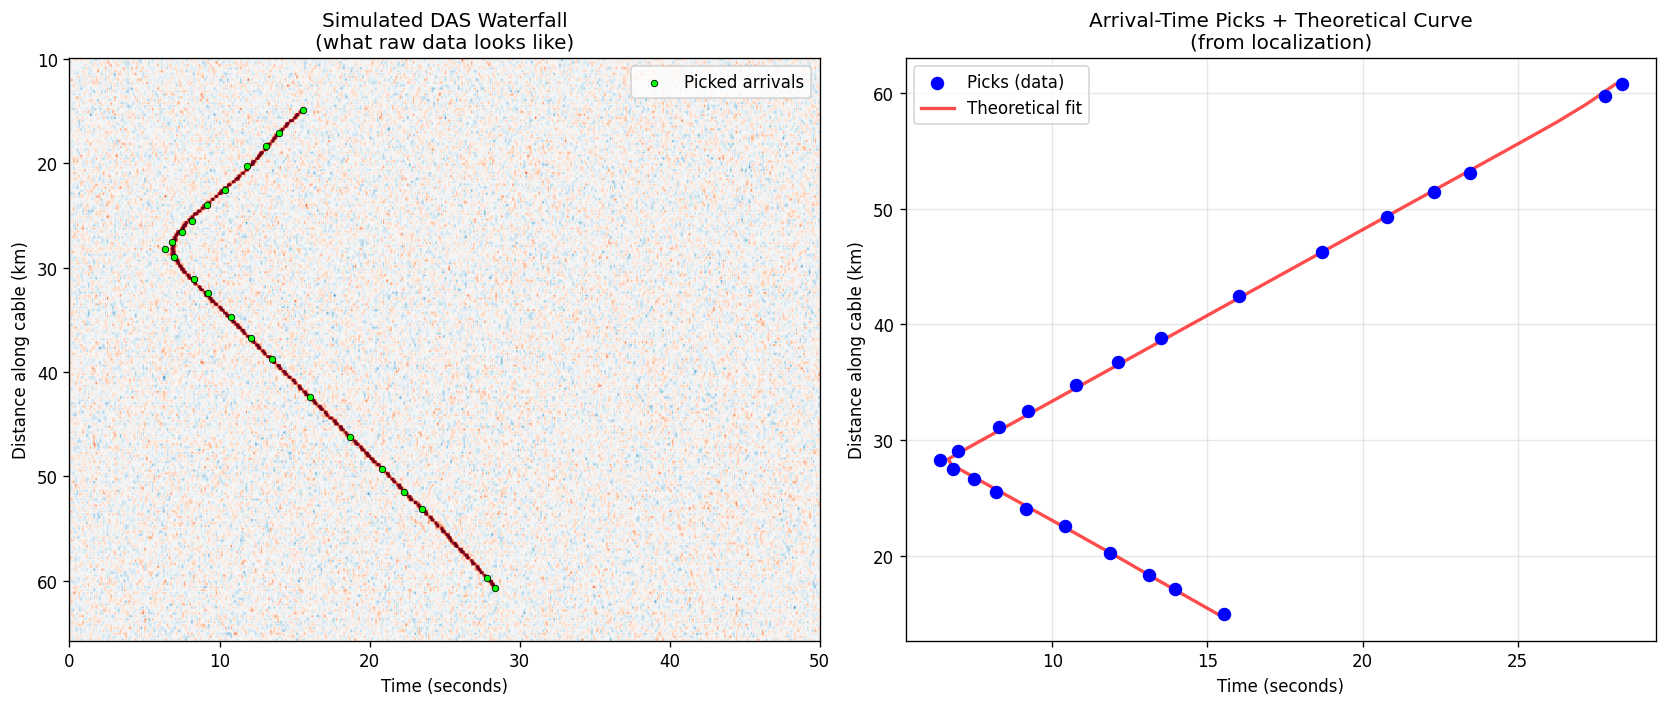

LEFT: What the raw DAS data looks like (channel × time image)
  - The bright curved streak = the whale call propagating along the cable
  - Green dots = the picked arrival times (from annotations)

RIGHT: The picks alone with the theoretical best-fit curve
  - If the fit is good, the whale position estimate is accurate
  - Residuals (data - theory) reveal model errors


In [10]:
# Show what this looks like in the DAS "waterfall" view
# (This is what the raw NetCDF data looks like - simulated here)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Simulate a DAS waterfall for call 1
call1_n = ann_n[ann_n['call_id'] == 1].sort_values('dist')

# Create a simulated DAS image (what the raw data looks like)
n_channels = 200
n_time = 400
dist_range = np.linspace(call1_n['dist'].min() - 5000, call1_n['dist'].max() + 5000, n_channels)
time_range = np.linspace(0, 50, n_time)

# Build simulated waterfall (noise + signal along the arrival curve)
np.random.seed(42)
waterfall = np.random.randn(n_channels, n_time) * 0.3

# Add signal along the arrival curve (interpolated)
from scipy.interpolate import UnivariateSpline
try:
    sort_idx = np.argsort(call1_n['dist'].values)
    spl = UnivariateSpline(call1_n['dist'].values[sort_idx], 
                           call1_n['time'].values[sort_idx], s=0.5)
    for i, d in enumerate(dist_range):
        if call1_n['dist'].min() <= d <= call1_n['dist'].max():
            t_arrival = float(spl(d))
            t_idx = int((t_arrival / 50) * n_time)
            if 2 < t_idx < n_time - 2:
                waterfall[i, t_idx-1:t_idx+2] += np.array([1.5, 3.0, 1.5])
except:
    pass

ax = axes[0]
im = ax.imshow(waterfall, aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2,
               extent=[time_range[0], time_range[-1], dist_range[-1]/1000, dist_range[0]/1000])
ax.scatter(call1_n['time'], call1_n['dist']/1000, c='lime', s=15, 
           edgecolors='black', linewidths=0.5, zorder=5, label='Picked arrivals')
ax.set_xlabel('Time (seconds)')
ax.set_ylabel('Distance along cable (km)')
ax.set_title('Simulated DAS Waterfall\n(what raw data looks like)')
ax.legend(loc='upper right')

# Plot 2: Just the picks with theoretical fit
ax = axes[1]
ax.scatter(call1_n['time'], call1_n['dist']/1000, c='blue', s=50, 
           zorder=5, label='Picks (data)')

# Theoretical curve from our localization
whale_x_est, whale_y_est = 36936, 22198  # from earlier localization
t0_est = 6.515
theory_dist = np.linspace(call1_n['dist'].min(), call1_n['dist'].max(), 100)
theory_cx = interp_x_n(theory_dist)
theory_cy = interp_y_n(theory_dist)
theory_d = np.sqrt((whale_x_est - theory_cx)**2 + (whale_y_est - theory_cy)**2)
theory_t = t0_est + theory_d / 1480.0

ax.plot(theory_t, theory_dist/1000, 'r-', linewidth=2, label='Theoretical fit', alpha=0.7)
ax.set_xlabel('Time (seconds)')
ax.set_ylabel('Distance along cable (km)')
ax.set_title('Arrival-Time Picks + Theoretical Curve\n(from localization)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("LEFT: What the raw DAS data looks like (channel × time image)")
print("  - The bright curved streak = the whale call propagating along the cable")
print("  - Green dots = the picked arrival times (from annotations)")
print("\nRIGHT: The picks alone with the theoretical best-fit curve")
print("  - If the fit is good, the whale position estimate is accurate")
print("  - Residuals (data - theory) reveal model errors")

---
## 6. Physics-Based Localization (Grid Search) <a id="6-physics-based-localization"></a>

Now let's implement the actual localization algorithm step by step.

### The Algorithm:
1. For each candidate whale position `(wx, wy)` on a grid:
   - Compute distance from whale to each pick point on the cable
   - Compute predicted arrival time: `t_predicted = t0 + distance / c`
   - Find optimal `t0` (median of residuals, for L1 robustness)
   - Compute total misfit: `Σ |t_observed - t_predicted|`
2. The position with minimum misfit is the whale's estimated location
3. Refine with gradient-based optimization

In [11]:
def localize_whale(picks_x, picks_y, picks_t, c=1480.0, 
                   x_range=(10000, 80000), y_range=(10000, 35000), 
                   grid_size=80, refine=True):
    """
    Localize a whale from arrival-time picks using grid search + L1 minimization.
    
    Parameters:
        picks_x, picks_y: Physical coordinates of each pick point on the cable
        picks_t: Observed arrival times at each pick point
        c: Sound speed in water (m/s)
        x_range, y_range: Search area
        grid_size: Number of grid points per axis
        refine: Whether to refine with Nelder-Mead after grid search
    
    Returns:
        dict with 'x', 'y', 't0', 'residual', 'per_pick_residuals'
    """
    xs = np.linspace(x_range[0], x_range[1], grid_size)
    ys = np.linspace(y_range[0], y_range[1], grid_size)
    
    # Grid search
    best_residual = np.inf
    best_pos = None
    best_t0 = None
    
    # Vectorized grid search
    WX, WY = np.meshgrid(xs, ys)
    residual_map = np.zeros_like(WX)
    
    for i in range(len(ys)):
        for j in range(len(xs)):
            wx, wy = xs[j], ys[i]
            dists = np.sqrt((wx - picks_x)**2 + (wy - picks_y)**2)
            travel_times = dists / c
            t0 = np.median(picks_t - travel_times)
            residual = np.sum(np.abs(picks_t - (t0 + travel_times)))
            residual_map[i, j] = residual
            if residual < best_residual:
                best_residual = residual
                best_pos = (wx, wy)
                best_t0 = t0
    
    # Refine with optimization
    if refine:
        def objective(params):
            wx, wy, t0 = params
            dists = np.sqrt((wx - picks_x)**2 + (wy - picks_y)**2)
            return np.sum(np.abs(picks_t - (t0 + dists / c)))
        
        result = minimize(objective, [best_pos[0], best_pos[1], best_t0],
                         method='Nelder-Mead',
                         options={'xatol': 10, 'fatol': 0.001, 'maxiter': 10000})
        wx, wy, t0 = result.x
        final_residual = result.fun
    else:
        wx, wy, t0 = best_pos[0], best_pos[1], best_t0
        final_residual = best_residual
    
    # Compute per-pick residuals
    dists = np.sqrt((wx - picks_x)**2 + (wy - picks_y)**2)
    per_pick_res = picks_t - (t0 + dists / c)
    
    return {
        'x': wx, 'y': wy, 't0': t0,
        'residual': final_residual,
        'per_pick_residuals': per_pick_res,
        'residual_map': residual_map,
        'grid_xs': xs, 'grid_ys': ys
    }

In [12]:
# Localize call 1 using BOTH cables (L-2 style, but 2D for now)
call1_n = ann_n[ann_n['call_id'] == 1].copy()
call1_s = ann_s[ann_s['call_id'] == 1].copy()

# Map cable distance → physical coordinates
call1_n['cx'] = interp_x_n(call1_n['dist'].values)
call1_n['cy'] = interp_y_n(call1_n['dist'].values)
call1_s['cx'] = interp_x_s(call1_s['dist'].values)
call1_s['cy'] = interp_y_s(call1_s['dist'].values)

# Combine picks from both cables
all_picks = pd.concat([call1_n[['time', 'cx', 'cy']], call1_s[['time', 'cx', 'cy']]])

print(f"Localizing call 1 with {len(all_picks)} picks ({len(call1_n)} North + {len(call1_s)} South)...")
result = localize_whale(
    all_picks['cx'].values, all_picks['cy'].values, all_picks['time'].values,
    x_range=(20000, 55000), y_range=(12000, 30000), grid_size=80
)

print(f"\n=== LOCALIZATION RESULT ===")
print(f"Position: x = {result['x']:.0f} m, y = {result['y']:.0f} m")
print(f"Emission time (t0): {result['t0']:.3f} s")
print(f"Total L1 residual: {result['residual']:.2f} s")
print(f"Mean |residual| per pick: {np.mean(np.abs(result['per_pick_residuals'])):.3f} s")
print(f"  → equivalent to {np.mean(np.abs(result['per_pick_residuals'])) * 1480:.0f} m distance error")

Localizing call 1 with 41 picks (23 North + 18 South)...

=== LOCALIZATION RESULT ===
Position: x = 36933 m, y = 22200 m
Emission time (t0): 6.512 s
Total L1 residual: 4.60 s
Mean |residual| per pick: 0.112 s
  → equivalent to 166 m distance error


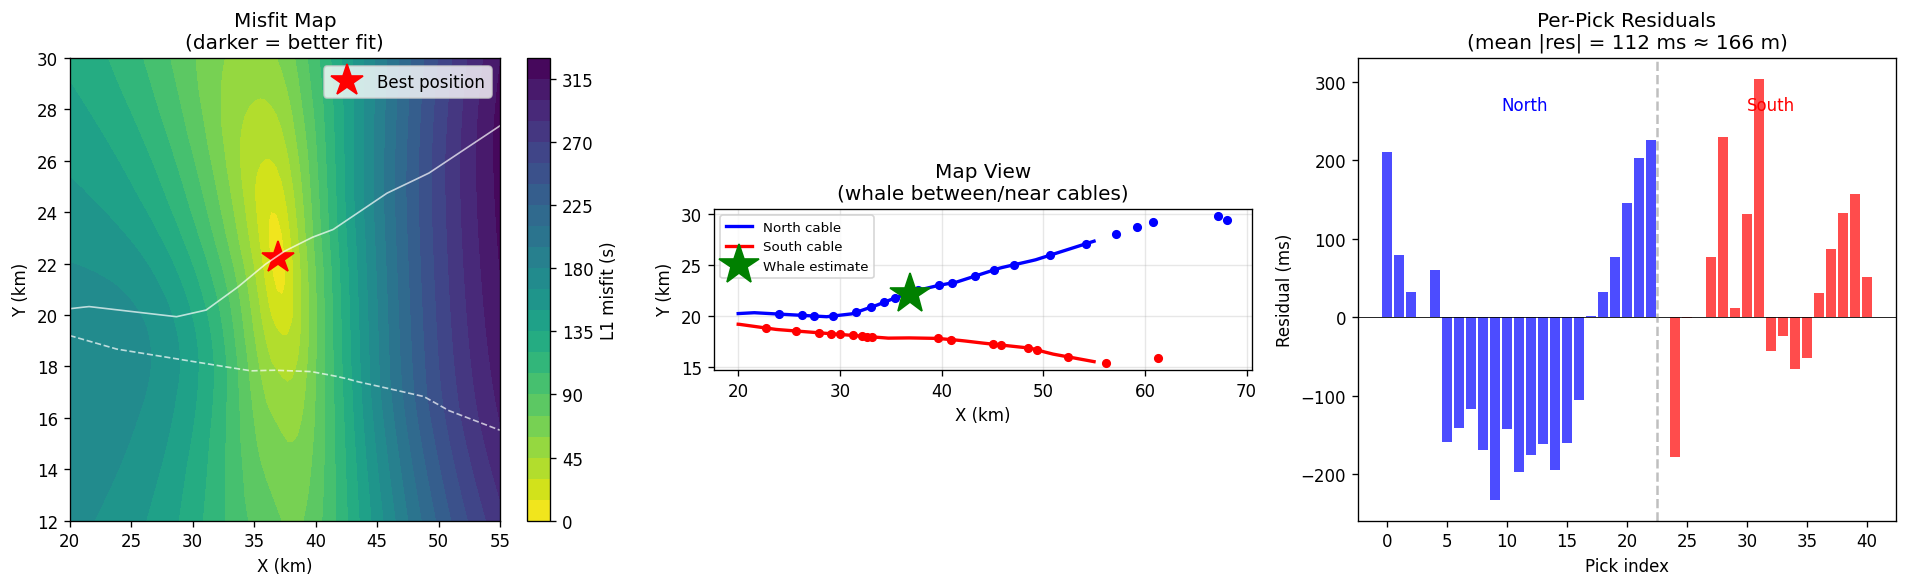

In [13]:
# Visualize the localization result
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Misfit map (shows where the solution lies)
ax = axes[0]
im = ax.contourf(result['grid_xs']/1000, result['grid_ys']/1000, 
                 result['residual_map'], levels=30, cmap='viridis_r')
ax.plot(result['x']/1000, result['y']/1000, 'r*', markersize=20, 
        label='Best position')
# Overlay cables
mask_n = (north_geo['x'] > 20000) & (north_geo['x'] < 55000)
mask_s = (south_geo['x'] > 20000) & (south_geo['x'] < 55000)
ax.plot(north_geo['x'].values[mask_n][::10]/1000, 
        north_geo['y'].values[mask_n][::10]/1000, 'w-', linewidth=1, alpha=0.7)
ax.plot(south_geo['x'].values[mask_s][::10]/1000, 
        south_geo['y'].values[mask_s][::10]/1000, 'w--', linewidth=1, alpha=0.7)
plt.colorbar(im, ax=ax, label='L1 misfit (s)')
ax.set_xlabel('X (km)')
ax.set_ylabel('Y (km)')
ax.set_title('Misfit Map\n(darker = better fit)')
ax.legend()

# Plot 2: Cable view with whale position
ax = axes[1]
ax.plot(north_geo['x'].values[mask_n]/1000, north_geo['y'].values[mask_n]/1000, 
        'b-', linewidth=2, label='North cable')
ax.plot(south_geo['x'].values[mask_s]/1000, south_geo['y'].values[mask_s]/1000, 
        'r-', linewidth=2, label='South cable')
ax.scatter(call1_n['cx']/1000, call1_n['cy']/1000, c='blue', s=20, zorder=5)
ax.scatter(call1_s['cx']/1000, call1_s['cy']/1000, c='red', s=20, zorder=5)
ax.plot(result['x']/1000, result['y']/1000, 'g*', markersize=25, 
        zorder=10, label='Whale estimate')
ax.set_xlabel('X (km)')
ax.set_ylabel('Y (km)')
ax.set_title('Map View\n(whale between/near cables)')
ax.legend(fontsize=8)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Plot 3: Residuals (fit quality)
ax = axes[2]
res = result['per_pick_residuals']
ax.bar(range(len(res)), res * 1000, color=['blue']*len(call1_n) + ['red']*len(call1_s),
       alpha=0.7)
ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel('Pick index')
ax.set_ylabel('Residual (ms)')
ax.set_title(f'Per-Pick Residuals\n(mean |res| = {np.mean(np.abs(res))*1000:.0f} ms ≈ {np.mean(np.abs(res))*1480:.0f} m)')
ax.axvline(len(call1_n)-0.5, color='gray', linestyle='--', alpha=0.5)
ax.text(len(call1_n)/2, ax.get_ylim()[1]*0.8, 'North', ha='center', color='blue')
ax.text(len(call1_n) + len(call1_s)/2, ax.get_ylim()[1]*0.8, 'South', ha='center', color='red')

plt.tight_layout()
plt.show()

In [14]:
# Compare L-1 (single cable) vs L-2 (both cables)
print("=== L-1 vs L-2 Comparison ===")
print()

# L-1: North only
result_n = localize_whale(
    call1_n['cx'].values, call1_n['cy'].values, call1_n['time'].values,
    x_range=(20000, 55000), y_range=(12000, 30000), grid_size=80
)

# L-1: South only  
result_s = localize_whale(
    call1_s['cx'].values, call1_s['cy'].values, call1_s['time'].values,
    x_range=(20000, 55000), y_range=(12000, 30000), grid_size=80
)

# L-2: Both
result_both = result  # already computed above

print(f"{'Method':<20} {'X (m)':<12} {'Y (m)':<12} {'Mean |res| (ms)':<18} {'≈ error (m)'}")
print("-" * 75)
print(f"{'L-1 North only':<20} {result_n['x']:<12.0f} {result_n['y']:<12.0f} "
      f"{np.mean(np.abs(result_n['per_pick_residuals']))*1000:<18.0f} "
      f"{np.mean(np.abs(result_n['per_pick_residuals']))*1480:.0f}")
print(f"{'L-1 South only':<20} {result_s['x']:<12.0f} {result_s['y']:<12.0f} "
      f"{np.mean(np.abs(result_s['per_pick_residuals']))*1000:<18.0f} "
      f"{np.mean(np.abs(result_s['per_pick_residuals']))*1480:.0f}")
print(f"{'L-2 Both cables':<20} {result_both['x']:<12.0f} {result_both['y']:<12.0f} "
      f"{np.mean(np.abs(result_both['per_pick_residuals']))*1000:<18.0f} "
      f"{np.mean(np.abs(result_both['per_pick_residuals']))*1480:.0f}")

print(f"\nDistance between L-1(N) and L-2: "
      f"{np.sqrt((result_n['x']-result_both['x'])**2 + (result_n['y']-result_both['y'])**2):.0f} m")
print(f"Distance between L-1(S) and L-2: "
      f"{np.sqrt((result_s['x']-result_both['x'])**2 + (result_s['y']-result_both['y'])**2):.0f} m")

=== L-1 vs L-2 Comparison ===

Method               X (m)        Y (m)        Mean |res| (ms)    ≈ error (m)
---------------------------------------------------------------------------
L-1 North only       36980        22319        122                180
L-1 South only       36949        21440        58                 87
L-2 Both cables      36933        22200        112                166

Distance between L-1(N) and L-2: 128 m
Distance between L-1(S) and L-2: 760 m


Localized 15 calls from this file


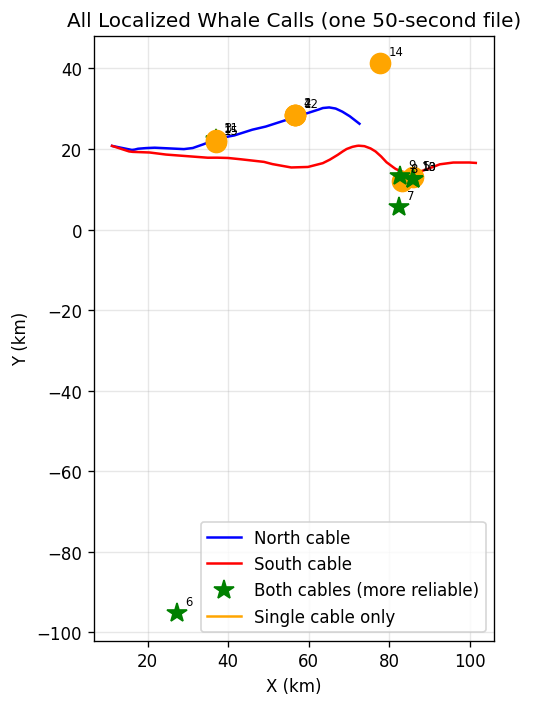


Note: Calls from the same whale should cluster together (same animal calling repeatedly)
Scattered positions may indicate multiple whales or localization errors


In [18]:
# Localize ALL shared calls to see the spread
results_all = []

for call_id in sorted(set(ann_n.call_id) | set(ann_s.call_id)):
    cn = ann_n[ann_n['call_id'] == call_id].copy()
    cs = ann_s[ann_s['call_id'] == call_id].copy()
    
    picks_list = []
    if len(cn) > 0:
        cn['cx'] = interp_x_n(cn['dist'].values)
        cn['cy'] = interp_y_n(cn['dist'].values)
        picks_list.append(cn[['time', 'cx', 'cy']])
    if len(cs) > 0:
        cs['cx'] = interp_x_s(cs['dist'].values)
        cs['cy'] = interp_y_s(cs['dist'].values)
        picks_list.append(cs[['time', 'cx', 'cy']])
    
    if not picks_list:
        continue
    
    all_p = pd.concat(picks_list)
    if len(all_p) < 5:  # need minimum picks
        continue
        
    r = localize_whale(
        all_p['cx'].values, all_p['cy'].values, all_p['time'].values,
        x_range=(15000, 65000), y_range=(10000, 32000), grid_size=60
    )
    r['call_id'] = call_id
    r['n_picks'] = len(all_p)
    r['has_north'] = len(cn) > 0
    r['has_south'] = len(cs) > 0
    results_all.append(r)

print(f"Localized {len(results_all)} calls from this file")

# Plot all localizations on the map
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

ax.plot(north_geo['x'].values[::10]/1000, north_geo['y'].values[::10]/1000,
        'b-', linewidth=1.5, label='North cable')
ax.plot(south_geo['x'].values[::10]/1000, south_geo['y'].values[::10]/1000,
        'r-', linewidth=1.5, label='South cable')

for r in results_all:
    marker = '*' if (r['has_north'] and r['has_south']) else 'o'
    color = 'green' if (r['has_north'] and r['has_south']) else 'orange'
    ax.plot(r['x']/1000, r['y']/1000, marker, color=color, markersize=12)
    ax.annotate(str(r['call_id']), (r['x']/1000, r['y']/1000), 
               fontsize=7, textcoords='offset points', xytext=(5, 5))

ax.plot([], [], 'g*', markersize=12, label='Both cables (more reliable)')
ax.plot([], [], '-', color='orange', markersize=8, label='Single cable only')
ax.set_xlabel('X (km)')
ax.set_ylabel('Y (km)')
ax.set_title('All Localized Whale Calls (one 50-second file)')
ax.legend()
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nNote: Calls from the same whale should cluster together (same animal calling repeatedly)")
print("Scattered positions may indicate multiple whales or localization errors")

---
## 7. Where ML Fits In <a id="7-where-ml-fits-in"></a>

Now that you understand the physics, here's where ML can improve things:

### The Localization Pipeline

```
Raw DAS data → [STEP 1: Detection] → [STEP 2: Arrival Picking] → [STEP 3: Localization]
  (NetCDF)        Find calls             Measure times              Estimate position
```

ML can replace or augment **any** of these steps:

### Option A: ML for Step 2 (Arrival Picking)
- **Input**: DAS waterfall image (channel × time) around a detected call
- **Output**: Arrival time at each channel (regression or segmentation)
- **Why**: The provided picks are sparse and may miss low-SNR channels. ML can fill gaps.
- **Architecture**: UNet or Mask R-CNN (like DASNet did)

### Option B: ML for Step 3 (Localization from Picks)
- **Input**: The arrival-time curve (a 1D sequence of (distance, time) pairs)
- **Output**: Position (x, y) or (x, y, z)
- **Why**: Can learn non-constant sound speed, bathymetry effects, cable position errors
- **Architecture**: 1D CNN, Transformer, or even MLP on curve features

### Option C: End-to-End (Steps 1+2+3 combined)
- **Input**: Raw DAS patch
- **Output**: Position directly
- **Why**: Avoids error propagation between steps
- **Architecture**: 2D CNN or ViT on the DAS image

### Option D: Physics-Informed ML (Hybrid)
- **Step 1**: Physics gives initial estimate
- **Step 2**: ML learns to correct systematic errors
- **Input to ML**: Physics estimate + curve features + cable geometry
- **Output**: Correction vector (Δx, Δy)
- **Why**: Gets physics-level accuracy on easy cases + ML correction on hard ones

In [19]:
# Demonstrate Option B: Simple ML for localization from picks
# (Feature engineering approach)

print("=== Feature Engineering for ML Localization ===")
print()
print("Given an arrival-time curve, what features encode position?")
print()

# For call 1, extract interpretable features
call1_n_sorted = ann_n[ann_n['call_id'] == 1].sort_values('dist')

dists = call1_n_sorted['dist'].values
times = call1_n_sorted['time'].values

# Feature 1: Position of minimum time (closest cable point)
min_idx = np.argmin(times)
f_min_dist = dists[min_idx]
f_min_time = times[min_idx]

# Feature 2: Curvature at minimum (relates to perpendicular distance)
# Approximate with parabola fit near minimum
near_min = (np.abs(np.arange(len(times)) - min_idx) <= 3)
if sum(near_min) >= 3:
    p = np.polyfit(dists[near_min] - f_min_dist, times[near_min], 2)
    f_curvature = p[0]  # coefficient of x^2 term
else:
    f_curvature = 0

# Feature 3: Asymmetry (left slope vs right slope)
left_picks = times[:min_idx] if min_idx > 0 else []
right_picks = times[min_idx+1:] if min_idx < len(times)-1 else []

if len(left_picks) > 1 and len(right_picks) > 1:
    left_slope = (left_picks[0] - times[min_idx]) / (dists[0] - f_min_dist)
    right_slope = (right_picks[-1] - times[min_idx]) / (dists[-1] - f_min_dist)
    f_asymmetry = left_slope / right_slope if right_slope != 0 else 0
else:
    f_asymmetry = 1.0

# Feature 4: Total time spread
f_time_spread = times.max() - times.min()

# Feature 5: Spatial coverage
f_dist_spread = (dists.max() - dists.min()) / 1000  # km

print(f"Feature 1 - Min-time distance along cable: {f_min_dist/1000:.1f} km")
print(f"  → Tells you WHERE along the cable the whale is closest")
print(f"")
print(f"Feature 2 - Curvature at minimum: {f_curvature*1e6:.2f} × 10⁻⁶ s/m²")
print(f"  → Smaller curvature = whale is FARTHER from cable")
print(f"  → For a straight cable: curvature ≈ 1/(c × distance)")
print(f"  → Estimated distance: ~{1/(abs(f_curvature) * 1480 + 1e-10)/1000:.1f} km")
print(f"")
print(f"Feature 3 - Asymmetry (left/right slopes): {f_asymmetry:.2f}")
print(f"  → =1 means symmetric (whale perpendicular to cable)")
print(f"  → ≠1 means whale is off-axis (asymmetric V-shape)")
print(f"")
print(f"Feature 4 - Time spread: {f_time_spread:.1f} s")
print(f"Feature 5 - Distance coverage: {f_dist_spread:.1f} km")
print(f"")
print(f"→ An ML model (even a simple MLP) could learn: features → (x, y)")
print(f"→ With enough training examples, it can capture effects that")
print(f"   the physics model misses (sound speed variations, cable errors)")

=== Feature Engineering for ML Localization ===

Given an arrival-time curve, what features encode position?

Feature 1 - Min-time distance along cable: 28.3 km
  → Tells you WHERE along the cable the whale is closest

Feature 2 - Curvature at minimum: 0.16 × 10⁻⁶ s/m²
  → Smaller curvature = whale is FARTHER from cable
  → For a straight cable: curvature ≈ 1/(c × distance)
  → Estimated distance: ~4.1 km

Feature 3 - Asymmetry (left/right slopes): -1.02
  → =1 means symmetric (whale perpendicular to cable)
  → ≠1 means whale is off-axis (asymmetric V-shape)

Feature 4 - Time spread: 22.0 s
Feature 5 - Distance coverage: 45.8 km

→ An ML model (even a simple MLP) could learn: features → (x, y)
→ With enough training examples, it can capture effects that
   the physics model misses (sound speed variations, cable errors)


### Key Insight for ML: What is the "image" here?

If you think in terms of your BioDCASE experience:

| BioDCASE (Detection) | DCLDE (Localization) |
|---|---|
| Input: spectrogram (freq × time) | Input: DAS waterfall (channel × time) |
| Signal: horizontal/diagonal streaks | Signal: hyperbolic curve |
| Output: is call present? (classification) | Output: where is the source? (regression) |
| Axis meaning: frequency | Axis meaning: physical distance |
| Resolution: ~0.25s | Resolution: ~5ms |

The core ML task is almost the same: extract meaningful patterns from a 2D image. The difference is that here the pattern (hyperbola shape) has a direct physical interpretation that you can exploit.

---
## 8. Previous DCLDE Results & State of the Art <a id="8-previous-results"></a>

### History of DCLDE Localization Challenges

| Year | Challenge | Species | Sensor | Best Method |
|------|-----------|---------|--------|-------------|
| 2024 | First localization challenge | North Atlantic Right Whale | Sonobuoy grid | Deep learning + Bayesian inversion |
| 2027 | **Current (DAS)** | Fin whale | DAS fiber-optic | TBD (you!) |

**Key finding:** Localization with large distributed arrays has NOT been extensively explored in previous DCLDE workshops. The 2024 workshop was the first to include it, and it used traditional sonobuoys (discrete sensors), not DAS.

### State of the Art for DAS Whale Localization

From the research literature (2023-2026):

| Paper | Method | Accuracy |
|-------|--------|----------|
| Wilcock et al. 2023 | TDOA + grid search | First demonstration on OOI DAS |
| Horne et al. 2025 | Cross-correlation + grid search + BFGS | ~100m at close range, degrades with distance |
| Goestchel et al. 2025 | Enhanced SNR + iterative pilot stacking | Better picks for localization |
| Zhang et al. 2026 (DASNet) | Mask R-CNN detection + physics localization | 0.04s arrival-time MAE, >400k calls detected |
| Goestchel et al. 2026 | Automated association + grid search | **This is the challenge dataset paper** |
| Wei et al. 2024 | DAS localization review | ~100m error typical |

### Key Takeaways

1. **~100m accuracy** is the current state of the art for DAS whale localization
2. All published approaches use **physics-based localization** (grid search + L1/L2 optimization)
3. ML is used for **detection and arrival-time picking**, not (yet) for localization itself
4. **No one has published end-to-end ML localization from DAS** — this is an open research direction
5. The main error sources are: sound speed uncertainty, cable position errors, multipath

### What Could Win This Challenge

Given the state of the art, a competitive approach might:

1. **Baseline**: Physics grid search (should get you ~100-200m accuracy)
2. **Improvement 1**: Better sound speed model (depth-dependent c)
3. **Improvement 2**: ML-refined arrival picks from the raw DAS data
4. **Improvement 3**: Physics-informed ML correction (learn residuals from physics baseline)
5. **Uncertainty**: Ensemble multiple sound speed assumptions → position distribution

For L-2 (3D), adding depth as a free parameter + using both fibers is the natural extension.

In [20]:
# Summary: What we know about the data
print("="*60)
print("SUMMARY: DCLDE 2027 LOCALIZATION CHALLENGE")
print("="*60)
print()
print("TASK:")
print("  L-1: Predict whale (x, y) from single fiber")
print("  L-2: Predict whale (x, y, z) from two fibers")
print()
print("DATA PROVIDED:")
print(f"  - Cable geometry: North ({north_geo['chan_m'].max()/1000:.0f} km, {len(north_geo)} channels)")
print(f"                    South ({south_geo['chan_m'].max()/1000:.0f} km, {len(south_geo)} channels)")
print(f"  - Annotations: 5 batches × 12 files/batch × 2 cables = 120 files")
print(f"  - Raw DAS: 120 NetCDF files (~0.5-1 GB each, ~80 GB total)")
print(f"  - Each annotation has ~10-20 calls with ~15-25 picks each")
print(f"  - Estimated total: ~600-1200 labeled whale calls")
print()
print("EVALUATION:")
print("  - 10 minutes of test data (released 2027)")
print("  - Predict: UTC time + position (UTM or Lat/Lon) + uncertainty")
print("  - Metric: likely position error (meters) — not yet specified precisely")
print()
print("APPROACH OPTIONS:")
print("  1. Physics-only (grid search from provided picks) → ~100-200m")
print("  2. ML picks + physics localization (DASNet-style)")
print("  3. End-to-end ML (DAS image → position)")
print("  4. Hybrid (physics + ML correction) → best bet for competition")
print()
print("IMMEDIATE NEXT STEPS:")
print("  1. Download all annotation files (small, ~1 MB total)")
print("  2. Build physics baseline on all training data")
print("  3. Analyze error patterns (what does physics get wrong?)")
print("  4. Download 1-2 raw DAS files to see actual data")
print("  5. Decide on ML approach based on error analysis")

SUMMARY: DCLDE 2027 LOCALIZATION CHALLENGE

TASK:
  L-1: Predict whale (x, y) from single fiber
  L-2: Predict whale (x, y, z) from two fibers

DATA PROVIDED:
  - Cable geometry: North (66 km, 31518 channels)
                    South (97 km, 46440 channels)
  - Annotations: 5 batches × 12 files/batch × 2 cables = 120 files
  - Raw DAS: 120 NetCDF files (~0.5-1 GB each, ~80 GB total)
  - Each annotation has ~10-20 calls with ~15-25 picks each
  - Estimated total: ~600-1200 labeled whale calls

EVALUATION:
  - 10 minutes of test data (released 2027)
  - Predict: UTC time + position (UTM or Lat/Lon) + uncertainty
  - Metric: likely position error (meters) — not yet specified precisely

APPROACH OPTIONS:
  1. Physics-only (grid search from provided picks) → ~100-200m
  2. ML picks + physics localization (DASNet-style)
  3. End-to-end ML (DAS image → position)
  4. Hybrid (physics + ML correction) → best bet for competition

IMMEDIATE NEXT STEPS:
  1. Download all annotation files (small, 